# Why are AI fix PRs not merged?
**Paper:** Alam, Mondal & Roy 2026 – Why Are AI Agent–Involved Pull Requests (Fix-Related) Remain Unmerged? (arXiv 2602.00164)
**Data:** Zenodo https://doi.org/10.5281/zenodo.18105922 (folder `Agents for Fixing`)

**What is in the data:** **AIDev-pop** (33,596 agent PRs, Dec 2024 → Jul 2025) **with the table `pr_task_type`** (each PR labelled feat / fix / docs…). The paper keeps the **8,106 fix PRs written by AI agents**, checks if they are merged, and labels by hand why 326 closed ones were not merged (12 failure reasons). ⚠️ These are **AI attempts to fix bugs**, not later fixes of AI code. ⭐ Big plus for us: this folder contains the AIDev tables that v4 removed (`pr_task_type`, `pr_timeline`, `related_issue`) – needed by **linker.py**.

**One row of the main table =** one AI pull request

This notebook has 3 parts:
1. **First look** – the files, some lines, all the columns, the size.
2. **Data-science view** – size, dates, **numbers per AI agent**, **how the agent is involved** (tables saved in `tables/`).
3. **Charts** – what kind of change · fixes per AI agent · who wrote the fix · how fast the fix comes · extra (saved in `charts/`).

In [1]:
import sys, os, json
sys.path.insert(0, "../..")          # to find common.py in the parent folder
from common import *

## 0. Get the data
Downloaded by hand from Zenodo into `Paper_Datasets/Agents for Fixing`.

In [2]:
DATA = None
for cand in [os.path.join(DATA_DIR, "Agents for Fixing"), os.path.join("..", "Agents for Fixing"), "Agents for Fixing"]:
    if os.path.exists(cand): DATA = cand; break
assert DATA, "Put the folder 'Agents for Fixing' in data/" + os.path.basename(os.getcwd())
print("Data folder:", DATA)

Data folder: ../../data/08_Alam_AI_Fix_PRs/Agents for Fixing


## 1. First look
### Files

In [3]:
list_files(DATA)

,file,size_MB
0,dataset/pull_request.parquet,16.86
1,dataset/pr_task_type.parquet,2.99
2,dataset/repository.parquet,0.17
3,dataset/related_issue.parquet,0.08
4,Results/RQ2/Failure Analysis of Fix related Unmerged Pul...,0.05
5,Results/RQ2/AgentWiseCategoryCount.csv,0.00


### Table 1: AIDev-pop pull requests

In [4]:
pr = pd.read_parquet(os.path.join(DATA, "dataset", "pull_request.parquet"))
_ = overview(pr.drop(columns=["body"]), "AIDev-pop pull requests")

**AIDev-pop pull requests** — **33,596 rows × 13 columns** (10.9 MB in memory)

*First 5 lines:*

,id,number,title,agent,user_id,user,state,created_at,closed_at,merged_at,repo_id,repo_url,html_url
0,3264933329,2911,Fix: Wait for all partitions in load_collection when som...,Claude_Code,108661493,weiliu1031,closed,2025-07-26T02:59:01Z,2025-07-29T07:01:20Z,NaN,191751505,https://api.github.com/repos/milvus-io/pymilvus,https://github.com/milvus-io/pymilvus/pull/2911
1,3265118634,2,ファイルパス参照を相対パスに統一し、doc/からdocs/に統一,Claude_Code,61827001,cm-kojimat,closed,2025-07-26T04:56:55Z,2025-07-26T22:12:24Z,2025-07-26T22:12:24Z,1025472321,https://api.github.com/repos/classmethod/tsumiki,https://github.com/classmethod/tsumiki/pull/2
2,3265640341,30,Add build staleness detection for debug CLI,Claude_Code,7475,MSch,closed,2025-07-26T13:31:19Z,2025-07-26T13:37:22Z,2025-07-26T13:37:22Z,988488798,https://api.github.com/repos/steipete/Peekaboo,https://github.com/steipete/Peekaboo/pull/30
3,3265709660,205,feat: add comprehensive README screenshots with optimize...,Claude_Code,80381,sugyan,closed,2025-07-26T14:07:22Z,2025-07-26T14:45:30Z,2025-07-26T14:45:30Z,999285986,https://api.github.com/repos/sugyan/claude-code-webui,https://github.com/sugyan/claude-code-webui/pull/205
4,3265782173,17625,chore: remove HashedPostStateProvider trait,Claude_Code,47593288,adust09,open,2025-07-26T15:02:48Z,NaN,NaN,537233603,https://api.github.com/repos/paradigmxyz/reth,https://github.com/paradigmxyz/reth/pull/17625


*All columns:*

,column,type,missing_%,unique,example
0,id,int64,0.0,33596,3264933329
1,number,int64,0.0,13195,2911
2,title,str,0.0,32332,Fix: Wait for all partitions in load_collection wh
3,agent,str,0.0,5,Claude_Code
4,user_id,int64,0.0,1797,108661493
5,user,str,0.0,1797,weiliu1031
6,state,str,0.0,2,closed
7,created_at,str,0.0,33437,2025-07-26T02:59:01Z
8,closed_at,str,6.9,30882,2025-07-29T07:01:20Z
9,merged_at,str,28.5,23978,2025-07-26T22:12:24Z


### Table 2: `pr_task_type` – the type of each PR (missing in AIDev v4!)

In [5]:
tt = pd.read_parquet(os.path.join(DATA, "dataset", "pr_task_type.parquet"))
_ = overview(tt, "PR task types")

**PR task types** — **33,596 rows × 6 columns** (8.3 MB in memory)

*First 5 lines:*

,agent,id,title,reason,type,confidence
0,Claude_Code,3264933329,Fix: Wait for all partitions in load_collection when som...,title provides conventional commit label,fix,10
1,Claude_Code,3265709660,feat: add comprehensive README screenshots with optimize...,title provides conventional commit label,feat,10
2,Claude_Code,3265782173,chore: remove HashedPostStateProvider trait,title provides conventional commit label,chore,10
3,Claude_Code,3231949586,feat(swagger): Add Swagger annotations to Batch 1 - Core...,title provides conventional commit label,feat,10
4,Claude_Code,3231950376,feat(swagger): Add Swagger annotations to Batch 2 - Cont...,title provides conventional commit label,feat,10


*All columns:*

,column,type,missing_%,unique,example
0,agent,str,0.0,5,Claude_Code
1,id,int64,0.0,33596,3264933329
2,title,str,0.0,32332,Fix: Wait for all partitions in load_collection wh
3,reason,str,0.0,23391,title provides conventional commit label
4,type,str,0.0,12,fix
5,confidence,int64,0.0,6,10


### Table 3: the 326 closed fix PRs labelled by hand

In [6]:
fa = pd.read_excel(os.path.join(DATA, "Results", "RQ2", "Failure Analysis of Fix related Unmerged Pull requests.xlsx"), sheet_name="Failure Analysis")
_ = overview(fa, "Failure reasons")

**Failure reasons** — **326 rows × 6 columns** (0.1 MB in memory)

*First 5 lines:*

,id,title,agent,html_url,Category,Detail Remarks
0,3167462922,Avoid Pods crashlooping when elasticsearch is unavailable,Copilot,https://github.com/camunda/camunda/pull/34153,Resolved by Another Pull Request,NaN
1,3125682958,Fix code-tunnel.exe completion trimming on Windows,Copilot,https://github.com/microsoft/vscode/pull/250894,Resolved by Another Pull Request,NaN
2,3125826357,Default to single resource in console logs when only one...,Copilot,https://github.com/dotnet/aspire/pull/9745,Resolved by Another Pull Request,NaN
3,3125850603,[WIP] Emitting Declarations for React Components require...,Copilot,https://github.com/microsoft/typescript-go/pull/1086,Resolved by Another Pull Request,NaN
4,3210960716,Fix SfExpander arrow color not restoring after cancelled...,Copilot,https://github.com/syncfusion/maui-toolkit/pull/217,Resolved by Another Pull Request,NaN


*All columns:*

,column,type,missing_%,unique,example
0,id,int64,0.0,326,3167462922
1,title,str,0.0,326,Avoid Pods crashlooping when elasticsearch is unav
2,agent,str,0.0,6,Copilot
3,html_url,str,0.0,326,https://github.com/camunda/camunda/pull/34153
4,Category,str,0.0,13,Resolved by Another Pull Request
5,Detail Remarks,str,66.6,60,ModuleNotFoundError: No module named 'psutil')


## 2. Data-science view
### Size and dates

In [7]:
pr["agent"] = pr["agent"].map(agent_of)
for c in ["created_at", "merged_at", "closed_at"]:
    pr[c] = pd.to_datetime(pr[c], utc=True, errors="coerce")
pr["outcome"] = pr.apply(lambda r: "merged" if pd.notna(r.merged_at) else ("closed" if r.state == "closed" else "open"), axis=1)
pr["hours_to_merge"] = (pr.merged_at - pr.created_at).dt.total_seconds() / 3600
fix = pr[pr.id.isin(tt[tt.type == "fix"].id)]
print("AIDev-pop PRs:", len(pr), "| repos:", pr.repo_id.nunique(), "| fix PRs:", len(fix))
print("Dates:", pr.created_at.min().date(), "->", pr.created_at.max().date())

AIDev-pop PRs: 33596 | repos: 2807 | fix PRs: 8106
Dates: 2024-12-24 -> 2025-07-30


### Numbers per AI agent (fix PRs)

In [8]:
per_agent = fix.groupby("agent").agg(fix_PRs=("id", "size"), merged=("outcome", lambda s: (s == "merged").sum()),
            closed=("outcome", lambda s: (s == "closed").sum()), open=("outcome", lambda s: (s == "open").sum()),
            median_hours_to_merge=("hours_to_merge", "median"))
per_agent["merge_%"] = (100 * per_agent.merged / per_agent.fix_PRs).round(1)
per_agent = per_agent.join(pr.groupby("agent").size().rename("all_PRs")).sort_values("fix_PRs", ascending=False)
save_table(per_agent.reset_index(), "per_agent")
per_agent

,fix_PRs,merged,closed,open,median_hours_to_merge,merge_%,all_PRs
agent,,,,,,,
Codex,4338,3539,616,183,0.022778,81.6,21799
Copilot,1993,845,713,435,18.111111,42.4,4970
Devin,1249,536,675,38,1.360972,42.9,4827
Cursor,411,281,84,46,0.297500,68.4,1541
Claude Code,115,66,25,24,0.595278,57.4,459


### How the agent is involved
The agent **opens a PR whose task is to fix a bug**. Maintainers merge it, close it, or leave it open.

In [9]:
summary_card("Alam et al. 2026", "AI pull request (fix-related)", len(fix), fix.repo_id.nunique(), str(pr.created_at.min().date()),
             str(pr.created_at.max().date()), ", ".join(per_agent.index), "Agent opens a fix PR; maintainers merge or reject it", "n/a (AI fix attempts, not fixes of AI code)")

,
paper,Alam et al. 2026
unit (1 row =),AI pull request (fix-related)
rows,8106
repos,1619
first date,2024-12-24
latest date,2025-07-30
agents,"Codex, Copilot, Devin, Cursor, Claude Code"
how the agent is involved,Agent opens a fix PR; maintainers merge or reject it
fixes of AI code,"n/a (AI fix attempts, not fixes of AI code)"


,paper,unit (1 row =),rows,repos,first date,latest date,agents,how the agent is involved,fixes of AI code
0,Alam et al. 2026,AI pull request (fix-related),8106,1619,2024-12-24,2025-07-30,"Codex, Copilot, Devin, Cursor, Claude Code",Agent opens a fix PR; maintainers merge or reject it,"n/a (AI fix attempts, not fixes of AI code)"


## 3. Charts
### Chart 1 · Task type of all AIDev-pop PRs

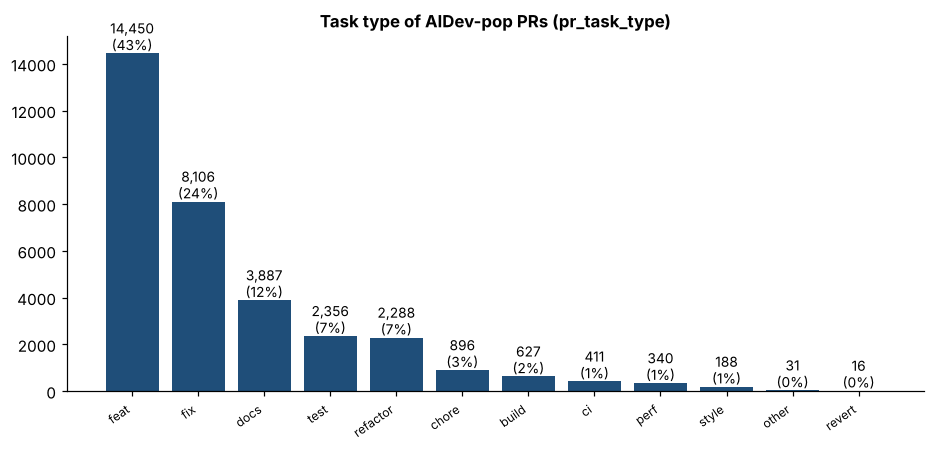

*Exact numbers – Task type of AIDev-pop PRs (pr_task_type)*

,number,%
type,,
feat,14450.0,43.0
fix,8106.0,24.1
docs,3887.0,11.6
test,2356.0,7.0
refactor,2288.0,6.8
chore,896.0,2.7
build,627.0,1.9
ci,411.0,1.2
perf,340.0,1.0


In [10]:
bar(tt["type"].value_counts(), "Task type of AIDev-pop PRs (pr_task_type)", "1_task_types.png", horizontal=True, pct=True)

### Chart 2 · Fix PRs per agent: merged, closed, open

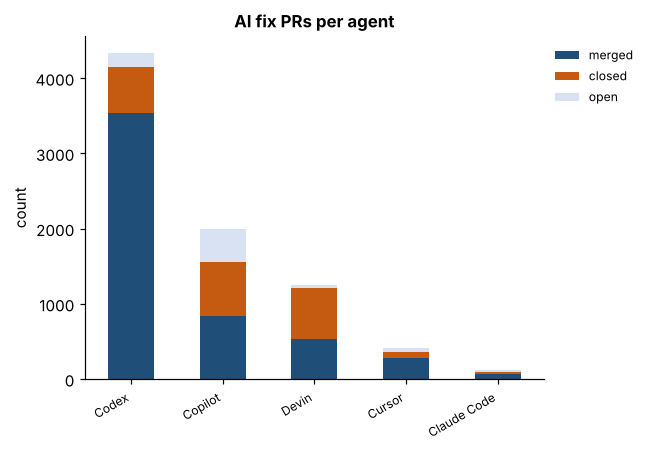

*Exact numbers – AI fix PRs per agent*

,merged,closed,open,TOTAL
agent,,,,
Claude Code,66,25,24,115
Cursor,281,84,46,411
Devin,536,675,38,1249
Copilot,845,713,435,1993
Codex,3539,616,183,4338
TOTAL,5267,2113,726,8106


In [11]:
stacked(per_agent[["merged", "closed", "open"]].iloc[::-1], "AI fix PRs per agent", "2_fix_prs_per_agent.png", colors=[BLUE, ORANGE, LIGHT])

### Chart 3 · Why closed fix PRs were not merged (326 labelled)

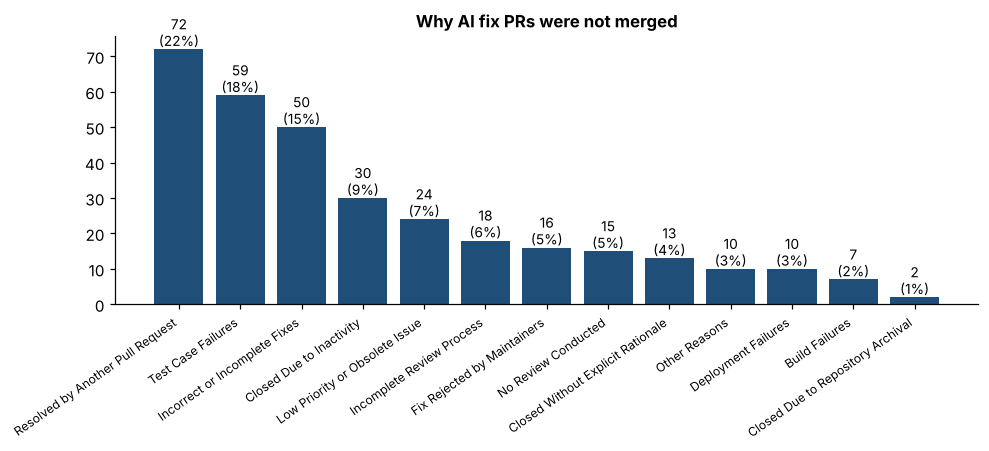

*Exact numbers – Why AI fix PRs were not merged*

,number,%
Category,,
Resolved by Another Pull Request,72.0,22.1
Test Case Failures,59.0,18.1
Incorrect or Incomplete Fixes,50.0,15.3
Closed Due to Inactivity,30.0,9.2
Low Priority or Obsolete Issue,24.0,7.4
Incomplete Review Process,18.0,5.5
Fix Rejected by Maintainers,16.0,4.9
No Review Conducted,15.0,4.6
Closed Without Explicit Rationale,13.0,4.0


In [12]:
bar(fa["Category"].value_counts(), "Why AI fix PRs were not merged", "3_failure_reasons.png", horizontal=True, pct=True)

### Chart 4 · How fast fix PRs are merged

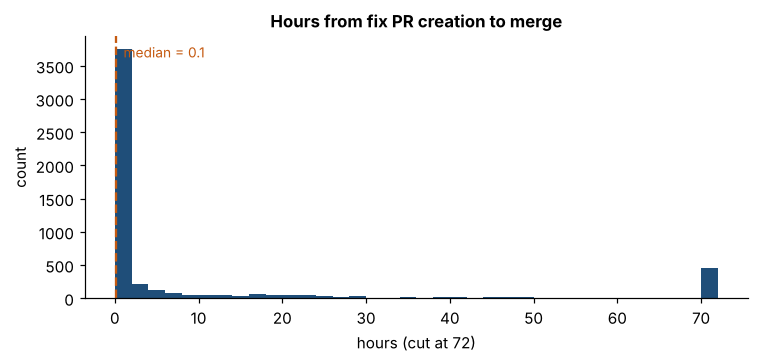

*Exact numbers – Hours from fix PR creation to merge*

,count,mean,std,min,25%,median,75%,max
hours (cut at 72),5267.0,9.96,21.64,0.0,0.01,0.11,3.7,72.0


In [13]:
hist(fix["hours_to_merge"].clip(upper=72), "Hours from fix PR creation to merge", "4_hours_to_merge.png", "hours (cut at 72)", bins=36)

## 4. Final figure

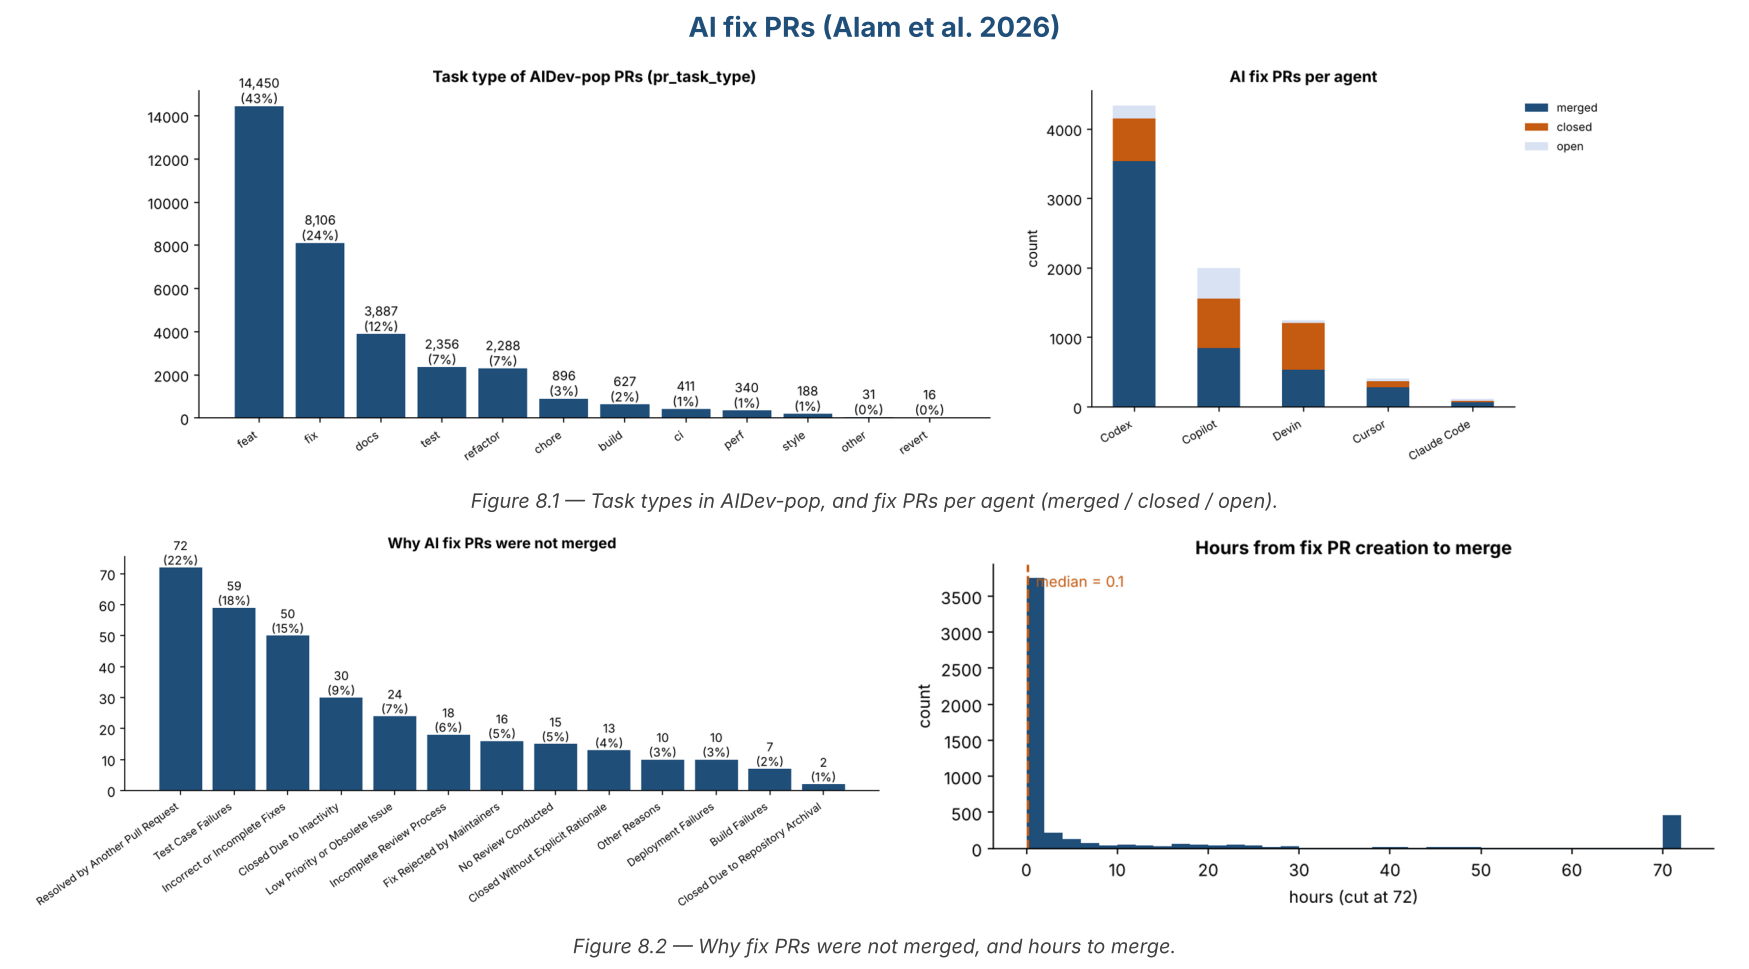

In [14]:
final_figure(8, "AI fix PRs (Alam et al. 2026)",
             "Task types in AIDev-pop, and fix PRs per agent (merged / closed / open).",
             "Why fix PRs were not merged, and hours to merge.")

## 5. Fixes
These are fixes **made by** AI agents (not fixes of AI code), so nothing is added to the final dataset.

⭐ **For linker.py:** `dataset/pr_task_type.parquet`, `pr_timeline.parquet` and `related_issue.parquet` are the AIDev-pop tables that v4 removed – copy them into `evolution-assurance/data/raw`.